In [1]:
from ai import MAB_Agent, Epsilon_Greedy_MAB_Agent
import matplotlib.pyplot as plt
import japanize_matplotlib

@staticmethod
def compare_mean_cumulative_reward_by_hparam(agent_list, hpname, steplist, miny=None, maxy=None):
    plt.title(f"{agent_list[0].NAME}\nステップ当たりの累積報酬の平均の比較（{agent_list[0].episodenum} エピソード）")
    for step in steplist:
        X = []
        Y = []
        for agent in agent_list:
            X.append(getattr(agent, hpname))
            Y.append(agent.mean_mean_coins_by_step[step])
        plt.plot(X, Y, label=f"ステップ数={step}")
    plt.xlabel(hpname)    
    plt.ylabel("ステップ当たりの累積報酬の平均")
    plt.ylim(miny, maxy)    
    plt.legend()
    plt.show()
    
MAB_Agent.compare_mean_cumulative_reward_by_hparam = compare_mean_cumulative_reward_by_hparam

In [2]:
egreedy_agents = []
for i in range(21):
    epsilon = i / 100
    egreedy_agent = MAB_Agent.load(f"../data/egreedy_agent(e={epsilon},step=1000)")
    egreedy_agents.append(egreedy_agent)

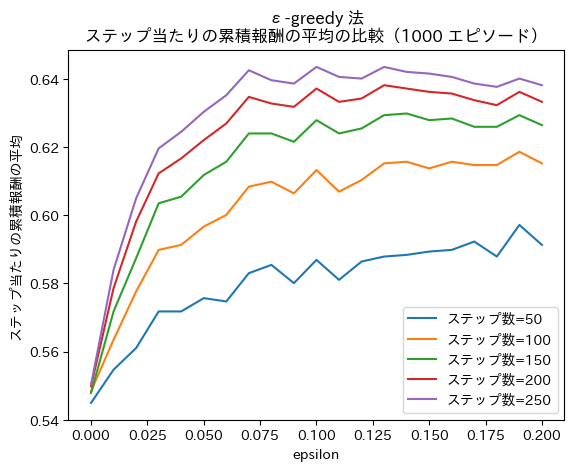

In [3]:
MAB_Agent.compare_mean_cumulative_reward_by_hparam(egreedy_agents, "epsilon", 
                                                   [50, 100, 150, 200, 250])

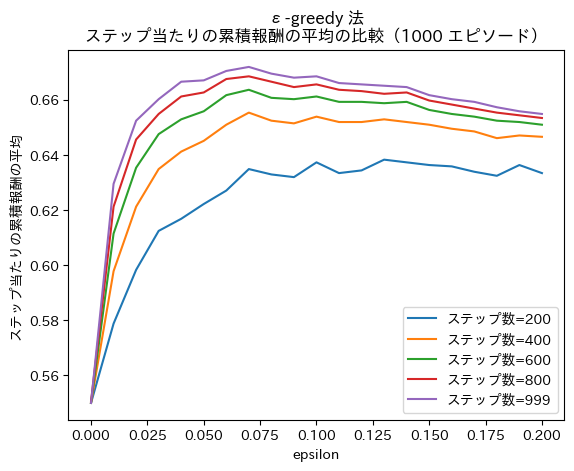

In [4]:
MAB_Agent.compare_mean_cumulative_reward_by_hparam(egreedy_agents, "epsilon",
                                                   [200, 400, 600, 800, 999])

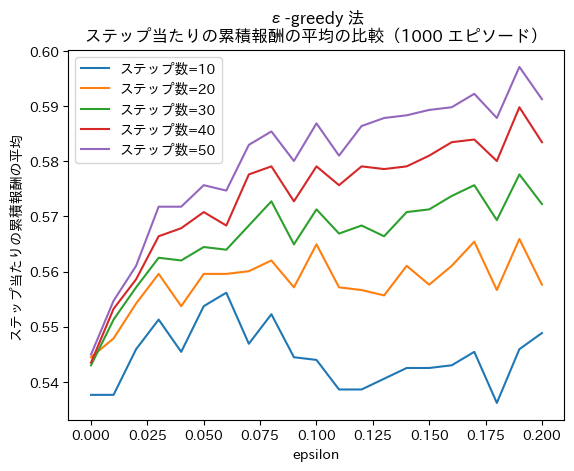

In [5]:
MAB_Agent.compare_mean_cumulative_reward_by_hparam(egreedy_agents, "epsilon",
                                                   [10, 20, 30, 40, 50])

In [6]:
mean_mean_coins_by_step_list = [ agent.mean_mean_coins_by_step for agent in egreedy_agents]

In [7]:
import numpy as np

best_index = np.argmax(mean_mean_coins_by_step_list, axis=0)
print(best_index)    

[ 8  8  8  8  6  6  6  6  6  6  6  6  6  6 17 17 17 17 17 17 19 19 19 19
 19 17 17 17 17 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19
 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19
 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19
 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19
 19 19 19 19 19 19 19 19 19 19 14 19 19 19 19 19 19 19 19 19 19 19 13 19
 13 13 13 13 13 13 14 14 14 14 14 14 14 14 14 14 14 14 14 14 13 14 14 13
 13 14 14 13 13 14 13 13 13 13 13 14 13 13 13 13 13 13 13 13 13 13 13 13
 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13
 13 13 13 13 13 13 13 13 13 13 13 10 13 13 10 10 10 13 10 10 10 10 10 13
 10 10 10 13 10 10 10 10 10 10 10 10 10 10 10 13 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7
  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7
  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7

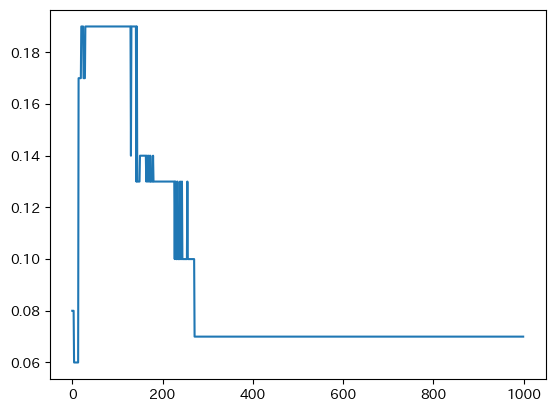

In [ ]:
best_hparams = [egreedy_agents[index].epsilon for index in best_index]
plt.plot(best_hparams)

In [9]:
@staticmethod
def draw_best_hparam_by_step(agent_list, hpname, miny=0, maxy=None):
    plt.title(f"{agent_list[0].NAME}\n最適なハイパーパラメータの推移（{agent_list[0].episodenum} エピソード）")
    mean_mean_coins_by_step_list = [ agent.mean_mean_coins_by_step for agent in agent_list]
    best_index = np.argmax(mean_mean_coins_by_step_list, axis=0)
    best_hparams = [getattr(agent_list[index], hpname) for index in best_index ]
    plt.plot(best_hparams)
    plt.xlabel("ステップ数")    
    plt.ylabel(hpname)
    plt.ylim(miny, maxy)    
    plt.show()    
    
MAB_Agent.draw_best_hparam_by_step = draw_best_hparam_by_step

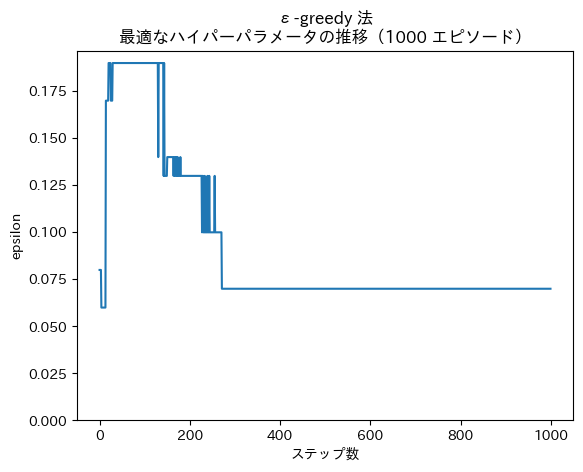

In [10]:
MAB_Agent.draw_best_hparam_by_step(egreedy_agents, "epsilon")

In [ ]:
p = [ 0.3, 0.5, 0.7 ]
egreedy_agents = egreedy_agents[:21]
for i in range(21, 31):
    epsilon = i / 100
    egreedy_agent = Epsilon_Greedy_MAB_Agent(p=p, epsilon=epsilon)
    egreedy_agent.play_episodes(stepnum=1000, episodenum=1000)
    egreedy_agent.save(f"../data/egreedy_agent(e={epsilon},step=1000)")

100%|██████████| 1000/1000 [00:36<00:00, 27.23it/s]


save completed.


100%|██████████| 1000/1000 [00:38<00:00, 25.85it/s]


save completed.


100%|██████████| 1000/1000 [00:37<00:00, 26.85it/s]


save completed.


... (10 outputs left out)

100%|██████████| 1000/1000 [00:37<00:00, 26.43it/s]


save completed.


100%|██████████| 1000/1000 [00:41<00:00, 23.98it/s]


save completed.


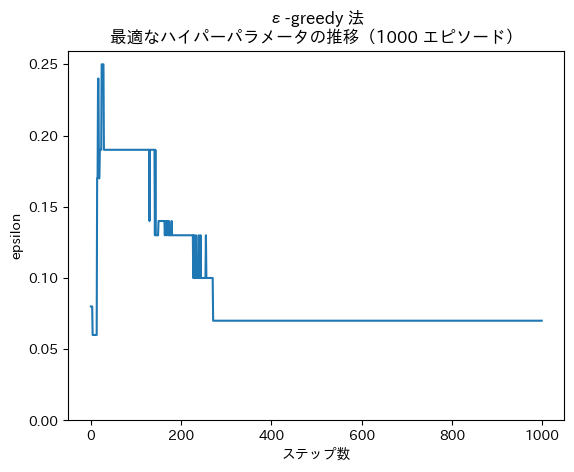

In [12]:
MAB_Agent.draw_best_hparam_by_step(egreedy_agents, "epsilon")

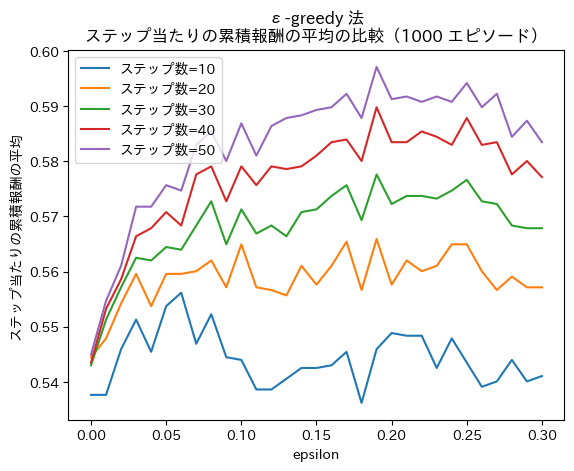

In [13]:
MAB_Agent.compare_mean_cumulative_reward_by_hparam(egreedy_agents, 
                                                   "epsilon", [10, 20, 30, 40, 50])

In [14]:
for epsilon in [0.065, 0.075]:
    egreedy_agent = Epsilon_Greedy_MAB_Agent(p=p, epsilon=epsilon)
    egreedy_agent.play_episodes(stepnum=1000, episodenum=1000)
    egreedy_agent.save(f"../data/egreedy_agent(e={epsilon},step=1000)")

100%|██████████| 1000/1000 [00:31<00:00, 31.52it/s]


save completed.


100%|██████████| 1000/1000 [00:38<00:00, 26.13it/s]


save completed.


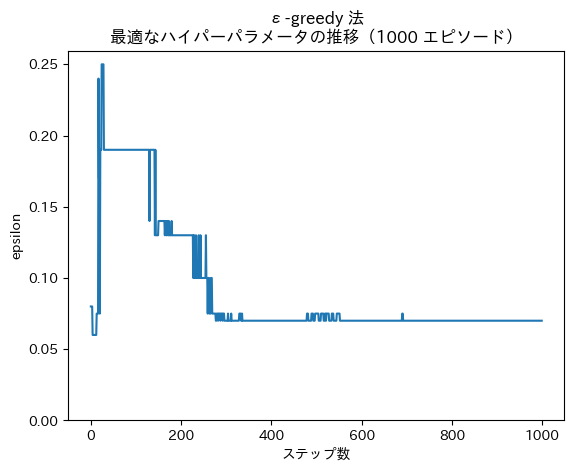

In [15]:
MAB_Agent.draw_best_hparam_by_step(egreedy_agents, "epsilon")

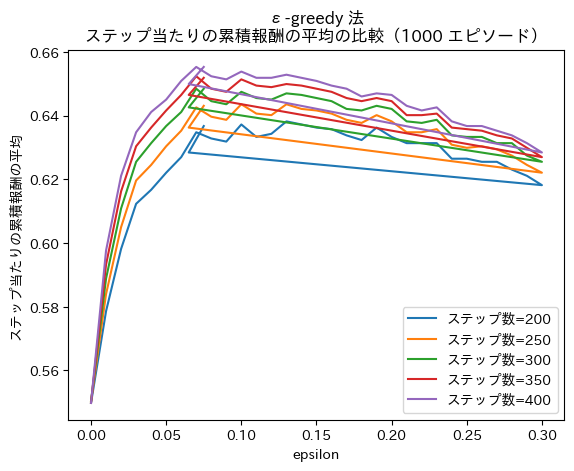

In [16]:
MAB_Agent.compare_mean_cumulative_reward_by_hparam(egreedy_agents, "epsilon", [200, 250, 300, 350, 400])

In [17]:
@staticmethod
def compare_mean_cumulative_reward_by_hparam(agent_list, hname, steplist, miny=None, maxy=None):
    plt.title(f"{agent_list[0].NAME}\nステップ当たりの累積報酬の平均の比較（{agent_list[0].episodenum} エピソード）")
    for step in steplist:
        X = []
        Y = []
        for agent in sorted(agent_list, key=lambda agent: getattr(agent, hname)):
            X.append(getattr(agent, hname))
            Y.append(agent.mean_mean_coins_by_step[step])
        plt.plot(X, Y, label=f"ステップ数={step}")
    plt.xlabel(hname)    
    plt.ylabel("ステップ当たりの累積報酬の平均")
    plt.ylim(miny, maxy)    
    plt.legend()
    plt.show()

MAB_Agent.compare_mean_cumulative_reward_by_hparam = compare_mean_cumulative_reward_by_hparam

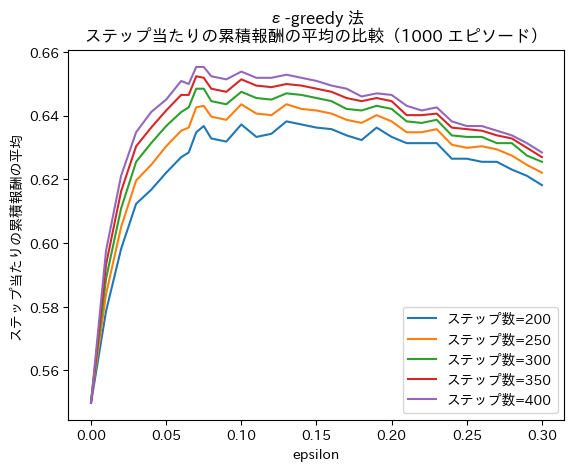

In [18]:
MAB_Agent.compare_mean_cumulative_reward_by_hparam(egreedy_agents, "epsilon", [200, 250, 300, 350, 400])